# 07 · From whiteboard photos to a training set (the preprocessing pipeline)

This notebook takes **all our own photos** (`board2notes_dataset_combined`, 250 photos), runs the preprocessing we presented in the hurdle slides, cuts every handwritten line out, pairs each line with its human label, and writes **one folder of labelled line crops** in PaddleOCR's text-recognition format. It does **not** split: the team merges this with the other datasets first and splits the merged set into training, validation and test. Every crop carries the columns that split needs (board, photo, repeat-shot group, text). Training is a separate step.

| Hurdle slide | Step | Code |
|---|---|---|
| 9 (Lighting) | lighting correction: flat-field, white balance, gamma, conditional CLAHE; never binarises | `preprocessing/fix_lighting.py` (Jian Yan, branch `Jy`, unchanged) |
| 7 (Perspective) | board edges + EXIF focal length -> homography | `preprocessing/board_geometry.py` (from `section8_auto_rectify_cells.ipynb`) |
| 9 (Rotation) | projection-profile sweep of the ink, gated | `preprocessing/fix_rotation.py` (Jian Yan, branch `Jy`, unchanged) |
| 6 (Blemish) | illumination division, NL-means, Otsu, blob filter | `preprocessing/blemish_removal.py` (from `BlemishRemovalTest.py`) |
| 8 (Zoom in) | lines shorter than 48 px enlarged (bicubic + sharpen), as the app does | `preprocessing/text_lines.py` |

**The order** (each arrow was a decision, see section 2):

```
photo -> lighting(light) -> quick detection -> perspective -> crop to the writing -> rotation (residual)
      -> lighting(strong) -> line detection -> [blemish removal] -> line crops -> enlarge small lines
      -> pair with labels -> one folder + labels.txt + manifest.csv   (split and augmentation: after merging)
```

**Why build the training set this way (and not reuse `crops/`)**
1. *Same pixels as the app.* Training crops go through exactly the preprocessing and enlargement the app applies before the reader. A reader trained on differently-made crops learns a different input distribution.
2. *No selection bias.* The old crops were kept only if the **pretrained** reader already read them with CER <= 0.25, so the hard lines (the ones worth training on) were thrown away and every test on them flattered the pretrained reader. Here the reader is used only to find which crop shows which label; whether the pairing is trusted also uses reading order and crop shape (`preprocessing/labels.py`).
3. *Ready for a fair split.* The manifest keeps board, photo and text per crop, so the merged set can be split by board (dataset README rule) and no handwriting or text lands in both training and test.

Kernel: **Python 3.12 (whiteboard-ocr)** (`.venv-paddle`). PaddleOCR runs on the CPU. Time: a few seconds per photo, about 15-25 minutes for all 250; it is **resumable** (finished photos are cached in `data/board2notes_rec_v2/rows/`).

## 0. Check and install the packages

Checks that every package this notebook needs is installed in **this kernel's** Python, and installs only what is missing, at the versions pinned in `whiteboard-ocr/requirements.txt` (the versions the project was tested with). Safe to re-run: when everything is there it changes nothing. If it installs something, restart the kernel (Kernel > Restart) and Run All again, so the new packages are loaded.

In [1]:
import importlib, importlib.util, re, subprocess, sys
from pathlib import Path

assert sys.version_info[:2] == (3, 12), (
    f"this kernel runs Python {sys.version.split()[0]}; PaddlePaddle needs Python 3.12: "
    "choose the 'Python 3.12 (whiteboard-ocr)' kernel (.venv-paddle)")

# import name -> pip package (and why it is needed)
NEEDED = {
    "numpy": "numpy",
    "cv2": "opencv-contrib-python",      # all image processing
    "PIL": "pillow",                     # EXIF focal length for the perspective correction
    "openpyxl": "openpyxl",              # the .xlsx label sheet
    "scipy": "scipy",                    # one-to-one pairing of crops and labels (Hungarian)
    "matplotlib": "matplotlib",          # figures
    "paddle": "paddlepaddle",            # PaddleOCR's engine
    "paddlex": "paddlex",
    "paddleocr": "paddleocr",            # text detection + recognition
}
EXTRA_PINS = {"scipy": "1.18.1"}         # tested version, not (yet) in requirements.txt

req = next((p / "requirements.txt" for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists()), None)
pins = dict(EXTRA_PINS)
if req:
    for line in req.read_text().splitlines():
        m = re.match(r"\s*([A-Za-z0-9_.\-]+)\s*==\s*([^\s#]+)", line)
        if m:
            pins[m.group(1).lower()] = m.group(2)

def installed(module):
    try:
        return importlib.util.find_spec(module) is not None
    except (ImportError, ValueError):
        return module in sys.modules

missing = [pkg for mod, pkg in NEEDED.items() if not installed(mod)]
tested_env = next((p / ".venv-paddle" for p in [Path.cwd(), *Path.cwd().parents] if (p / ".venv-paddle").is_dir()), None)
if missing and tested_env and not Path(sys.executable).resolve().is_relative_to(tested_env.resolve()):
    print(f"NOTE: this kernel is not the project's tested environment ({tested_env}), which already has every "
          "package.\n      Faster and safer: switch the kernel to 'Python 3.12 (whiteboard-ocr)' / .venv-paddle "
          "and re-run.\n      Installing into this kernel instead (PaddlePaddle is large: a few minutes).\n")
to_install = [f"{p}=={pins[p.lower()]}" if p.lower() in pins else p for p in missing]
print("kernel Python:", sys.executable)
print("requirements :", req or "not found (installing latest versions)")
if to_install:
    print("installing:", " ".join(to_install))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *to_install])
    importlib.invalidate_caches()
    print("\ninstalled. Now: Kernel > Restart, then Run All.")
else:
    print("all required packages are installed:", ", ".join(NEEDED.values()))

kernel Python: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Lab/.venv312/bin/python
requirements : /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/requirements.txt
all required packages are installed: numpy, opencv-contrib-python, pillow, openpyxl, scipy, matplotlib, paddlepaddle, paddlex, paddleocr


## 1. Setup and inventory

Paths are relative to `whiteboard-ocr/` (this notebook lives in `whiteboard-ocr/notebooks/`). The cell checks that every input exists before anything runs.

In [2]:
import os, sys, json, time
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
try:
    import torch  # on this Mac, torch must be imported before paddle when both are installed (section8 notebook)
except ImportError:
    pass          # torch is not needed by this notebook
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, cv2
import matplotlib.pyplot as plt

WB = Path.cwd().resolve()
WB = WB if (WB / "preprocessing").is_dir() else WB.parent          # works from whiteboard-ocr/ or notebooks/
sys.path.insert(0, str(WB))
import importlib
import preprocessing.labels, preprocessing.text_lines, preprocessing.board_geometry, preprocessing.pipeline, preprocessing.dataset
# reload, so that a changed .py file is used without restarting the kernel (Python caches imported modules)
for _m in (preprocessing.labels, preprocessing.text_lines, preprocessing.board_geometry, preprocessing.pipeline,
           preprocessing.dataset):
    importlib.reload(_m)
from preprocessing import labels as L, pipeline as P, text_lines as tl, board_geometry as geo, dataset as DS
from preprocessing import fix_lighting, fix_rotation, blemish_removal

ASSIGNMENT = WB.parent
DATASET    = ASSIGNMENT / "board2notes_dataset_combined"
OCT17_JSON = ASSIGNMENT / "17oct_rec_paddle" / "17oct_gt_lines.json"
OUT        = WB / "data" / "board2notes_rec_v2"
ORDER_DIR  = WB / "outputs" / "preprocess_order_r2"          # round 2 (on top of unclip 1.5) if it was run
ORDER_DIR  = ORDER_DIR if (ORDER_DIR / "decision.json").exists() else WB / "outputs" / "preprocess_order"
for p in (DATASET / "images", DATASET / "manifest.csv", DATASET / "labels" / "board2notes_labels_v1_textonly.xlsx",
          DATASET / "labels" / "oct17_name_map.csv", OCT17_JSON):
    assert p.exists(), f"missing input: {p}"
OUT.mkdir(parents=True, exist_ok=True)

manifest = L.load_manifest(DATASET)
gt = L.load_ground_truth(DATASET, OCT17_JSON)
photos = sorted(manifest)
print(f"photos: {len(photos)}  ({Counter(r['set'] for r in manifest.values())})")
print(f"photos with labels: {sum(1 for f in photos if gt.get(f))}, label lines: {sum(len(gt.get(f, [])) for f in photos)}")
print("boards:", Counter(r["board"] for r in manifest.values()))

photos: 250  (Counter({'17oct': 142, 'airdrop': 108}))
photos with labels: 149, label lines: 5280
boards: Counter({'oct17': 142, 'cnn': 49, 'quiz': 30, 'lecture': 13, 'television': 13, 'animal': 3})


## 2. Which steps, in which order? (decided by measurement, not by the slide order)

The slides show four steps, but not the order to run them in, and "it looks cleaner" is not evidence that the reader reads better. `scripts/preprocess_order_check.py` runs the chain with and without each step on a fixed sample of labelled photos and scores it with **the hurdle metrics** (line coverage, exact-line accuracy, CER, WER), overall and by condition. The keep/drop rule was written in the script before it was run: a step stays only if it lowers CER on the non-B3 photos by more than 0.01 and does not hurt B3 by more than 0.01.

What was already clear while building the steps (on our photos):

* **Rotation must come after the perspective correction and only on the text region.** On the whole photo, `fix_rotation` follows the room (floor lines, wall panels): it reported -72.6 deg (animal_01), +52.3 (cnn_17), +20.0 (quiz_12), +8.3 (quiz_03) on photos that are upright. On the text region it measures the writing (quiz_03: -1.4, conf 0.94). On the lecture board the column rulings fooled it into -85.7 deg, hence the gate (|angle| <= 15 deg, confidence >= 0.6).
* **Perspective needs a detection first**: it uses the text boxes to find the board and the edges around the writing. So one quick detection runs before it and the final detection runs after it.
* **Blemish removal binarises**: on faint or small writing (quiz_12, cnn_01) it breaks strokes. It is therefore optional and measured (variant V4); detection always runs on the colour image.

**What the measurement found (22 Oct, 44 photos, 7 variants).** Round 1: the biggest effect was not a preprocessing step but the detector setting `unclip_ratio`: at the baseline's 2.0 the detector merges neighbouring lines into one box; at 1.5, CER fell from 0.470 to 0.199 (95 % interval of the change -0.33 to -0.21; B3 0.421 -> 0.324). Blemish removal clearly hurt (+0.12 CER, interval above 0; B3 +0.31), rotation slightly (+0.04); perspective and lighting were within noise. Because every step had been measured with line-merging boxes, round 2 (`--round 2`) re-measures them on top of unclip 1.5; its decision rule (simplest chain within 0.01 CER of the best) was written down before it ran.

Run once in a terminal (from `Assignment/`; about 45 photos x 6 variants, 1-2 hours on the Mac CPU, resumable):
```
.venv-paddle/bin/python whiteboard-ocr/scripts/preprocess_order_check.py              # round 1
.venv-paddle/bin/python whiteboard-ocr/scripts/preprocess_order_check.py --round 2    # round 2
```
The next cell shows its result and takes the chosen chain from `decision.json`.

In [3]:
summary = ORDER_DIR / "summary.txt"
if summary.exists():
    print(summary.read_text())
    CHOSEN = json.loads((ORDER_DIR / "decision.json").read_text())["chosen"]
else:
    CHOSEN = "V2 light+persp+strong"
    print("preprocess_order_check.py has not been run yet -> using", CHOSEN, "(re-run this notebook after it)")
STEPS = P.VARIANTS[CHOSEN]
print("\nchain used for the dataset:", CHOSEN, "=", STEPS.name())

Preprocessing order check (hurdle metrics; reader = pretrained PP-OCRv6_medium_rec)
Scored on VISIBLE label lines: 662 of 1580 listed (a line is visible if any variant read it with CER <= 0.5; see rescore_visible)

Photos used to DECIDE (all boards except B3)
variant                      photos  lines   cover   exact     CER     WER  s/photo
R0 detector u1.5                 35    631   0.873   0.339   0.344   0.569      2.4
R0 detector u1.2                 35    631   0.941   0.407   0.219   0.431      2.5
R0 detector u1.8                 35    631   0.710   0.281   0.531   0.685      2.0
R1g persp>=9deg u1.5             35    631   0.881   0.331   0.328   0.564      3.5
R1 persp u1.5                    35    631   0.864   0.322   0.363   0.585      3.4
R2bg persp>=9+strong u1.5        35    631   0.859   0.334   0.313   0.532      4.1
R2b persp+strong u1.5            35    631   0.865   0.330   0.335   0.551      4.0
R2 light+persp+strong u1.5       35    631   0.864   0.322   0.366  

## 3. One photo through every step

A look at what each step does to one photo per condition (left to right: original, after lighting(light), after perspective + crop, after rotation, after lighting(strong), blemish-cleaned). Boxes: the final line detection.

/Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Lab/.venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Lab/.venv312/lib/python3.12/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/zhaobao/.paddlex/official_models/PP-OCRv5_mobile_det`.
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/zhaobao/.pa

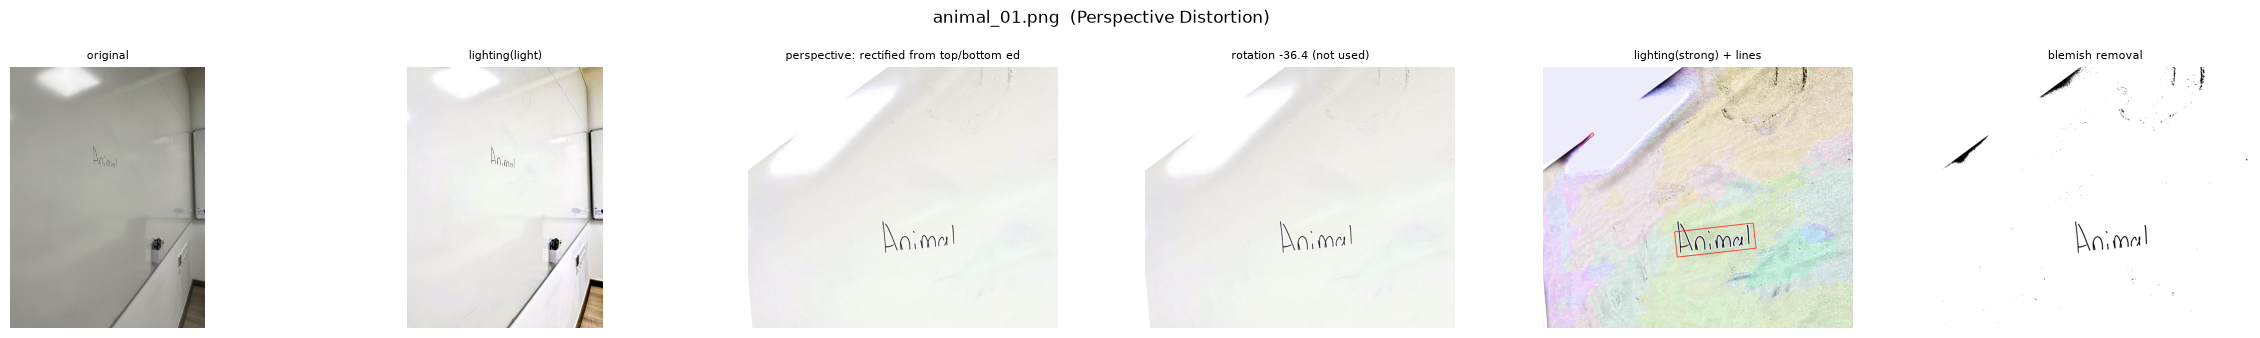

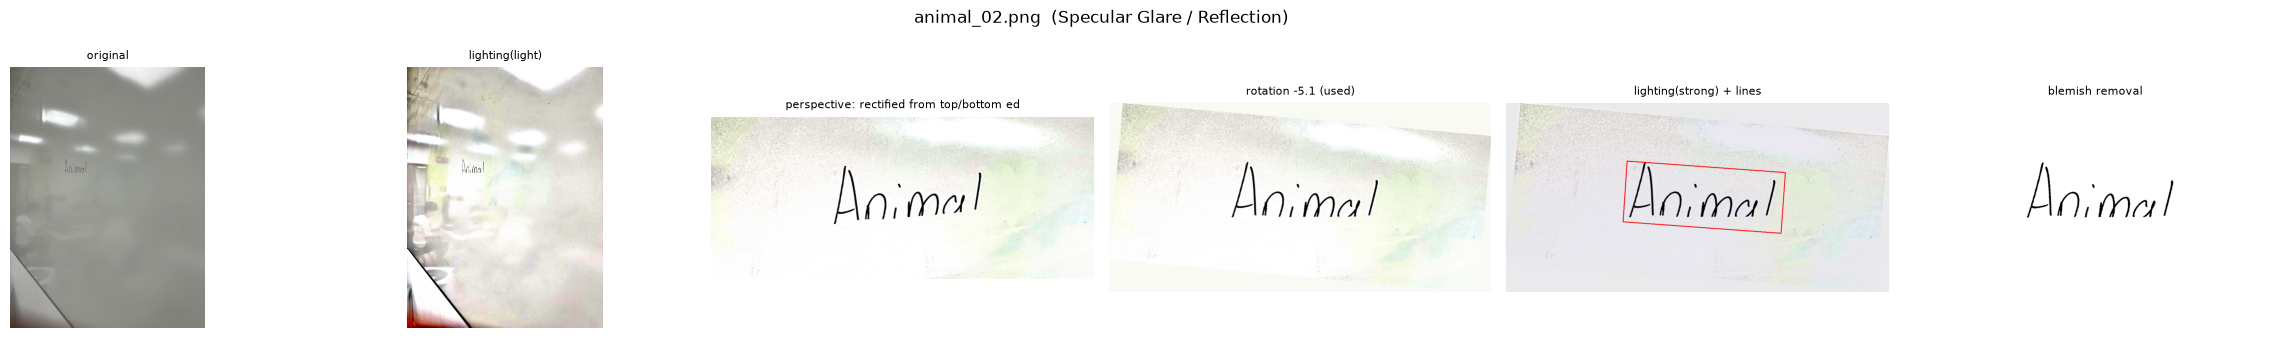

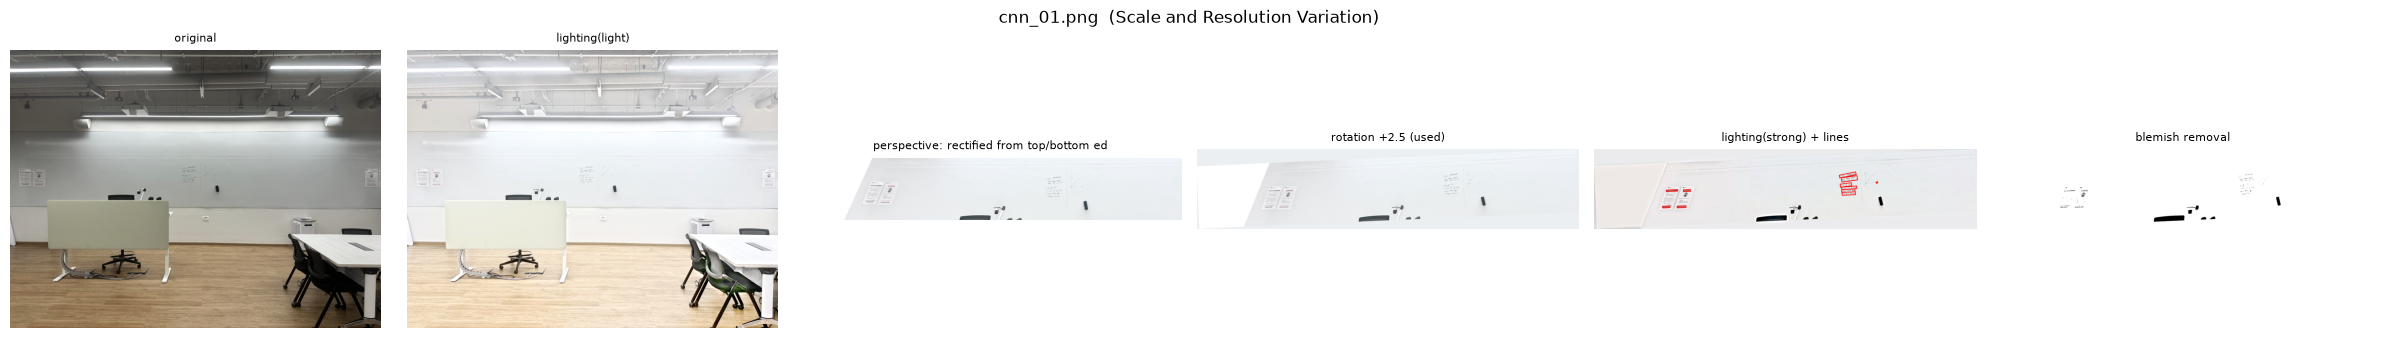

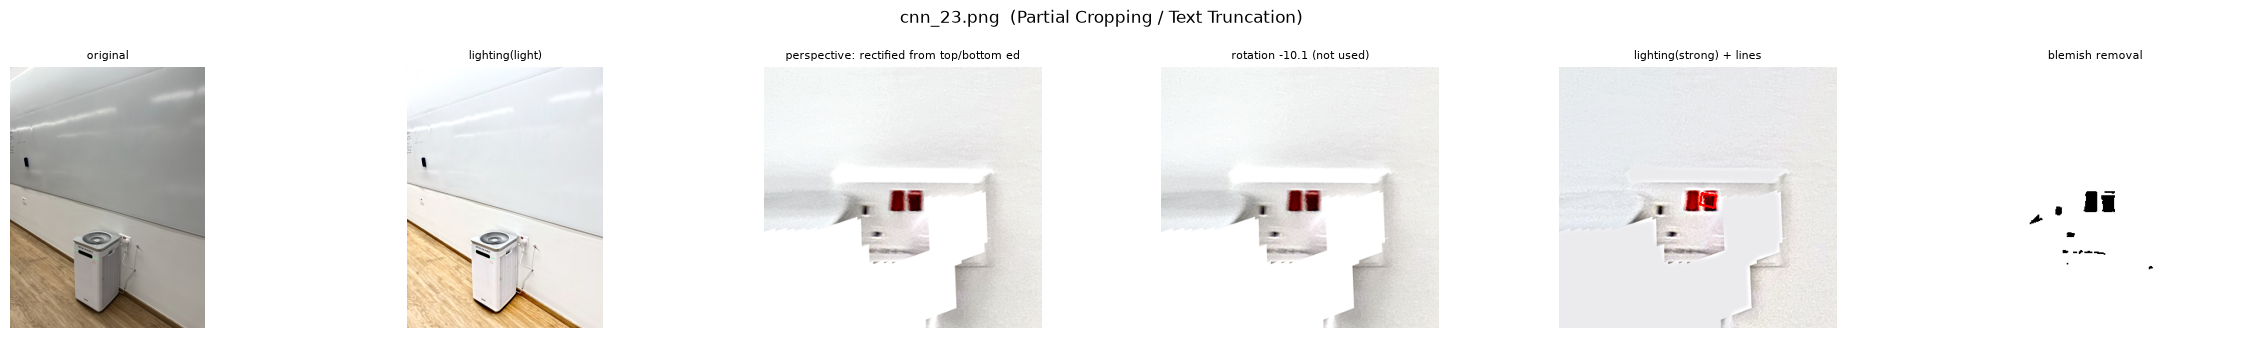

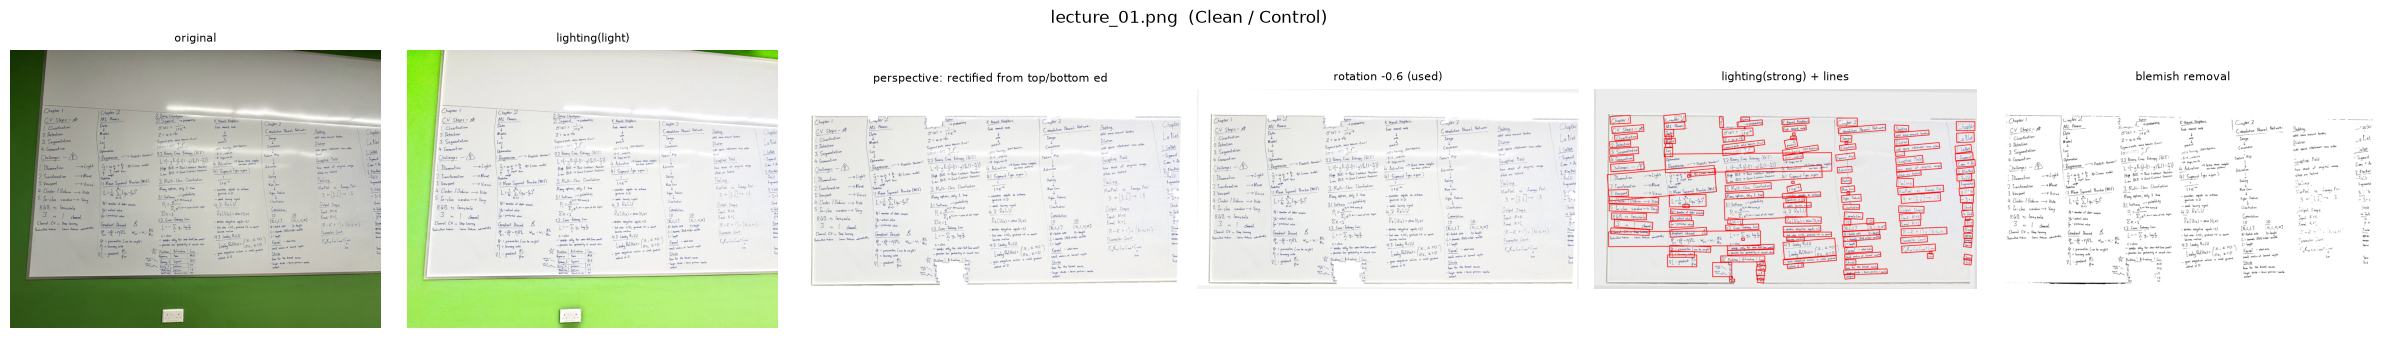

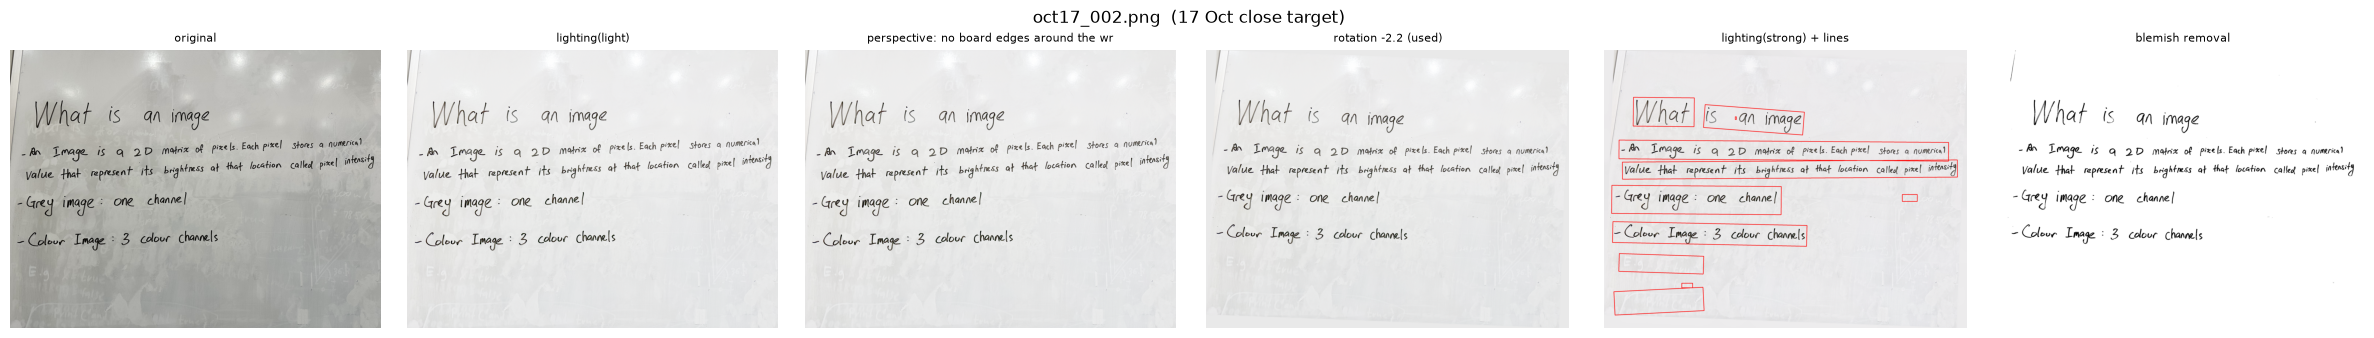

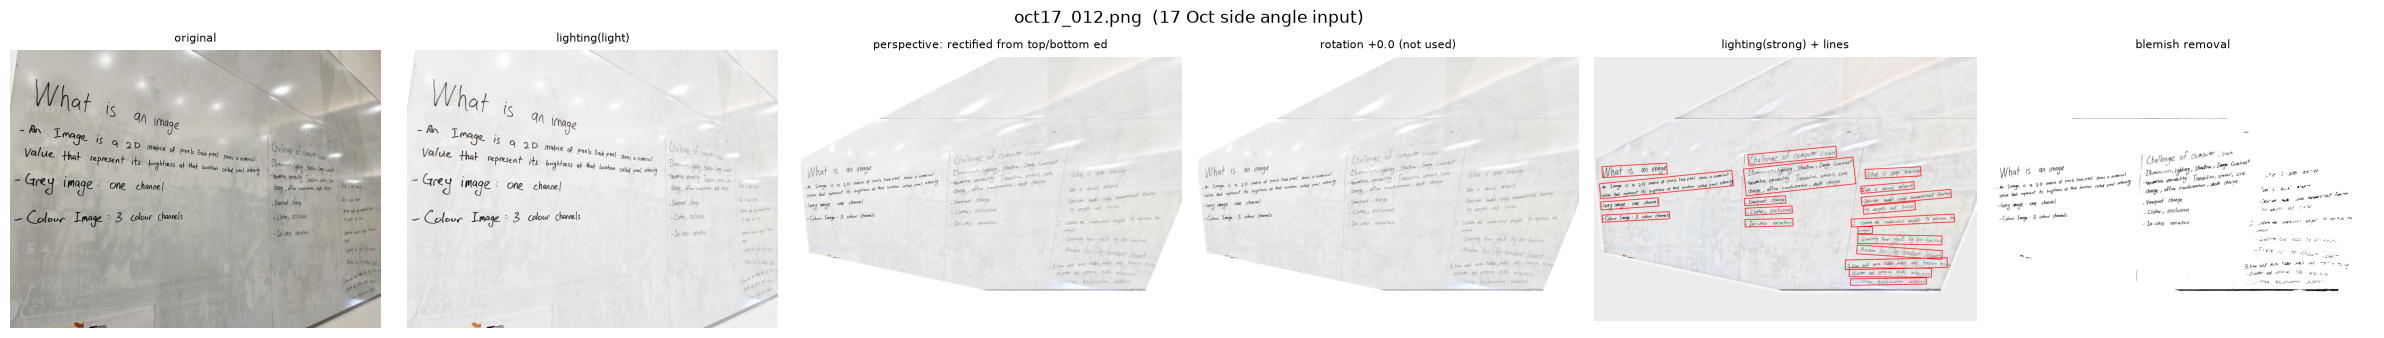

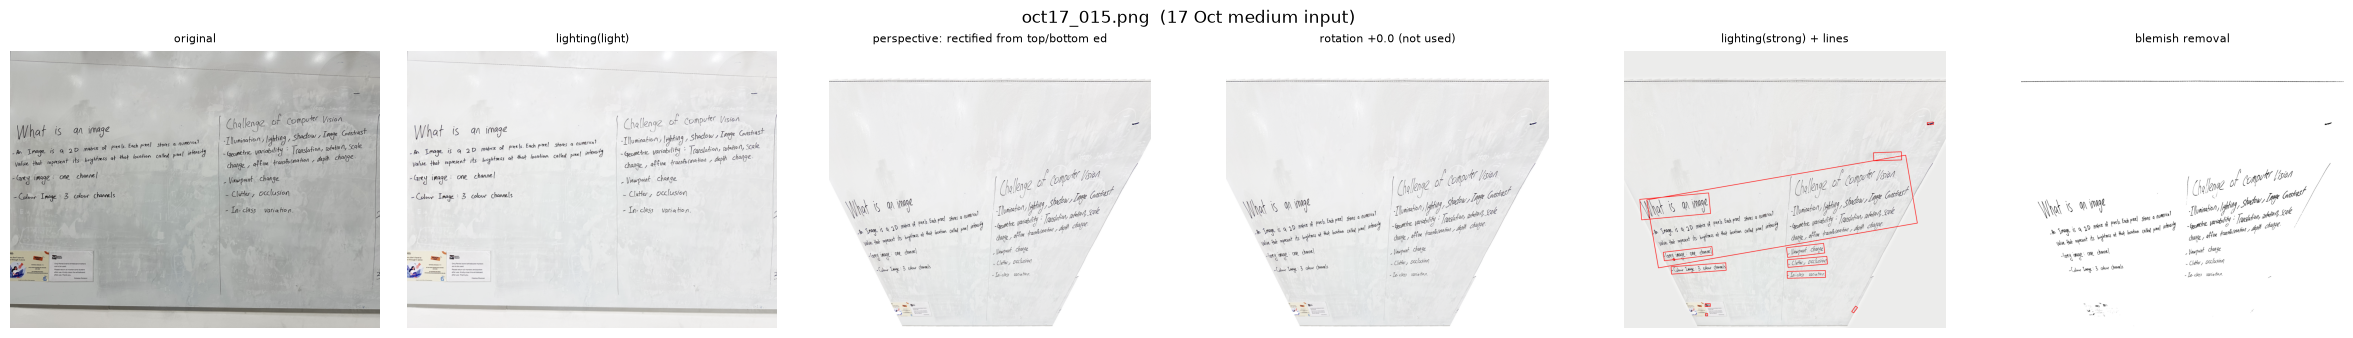

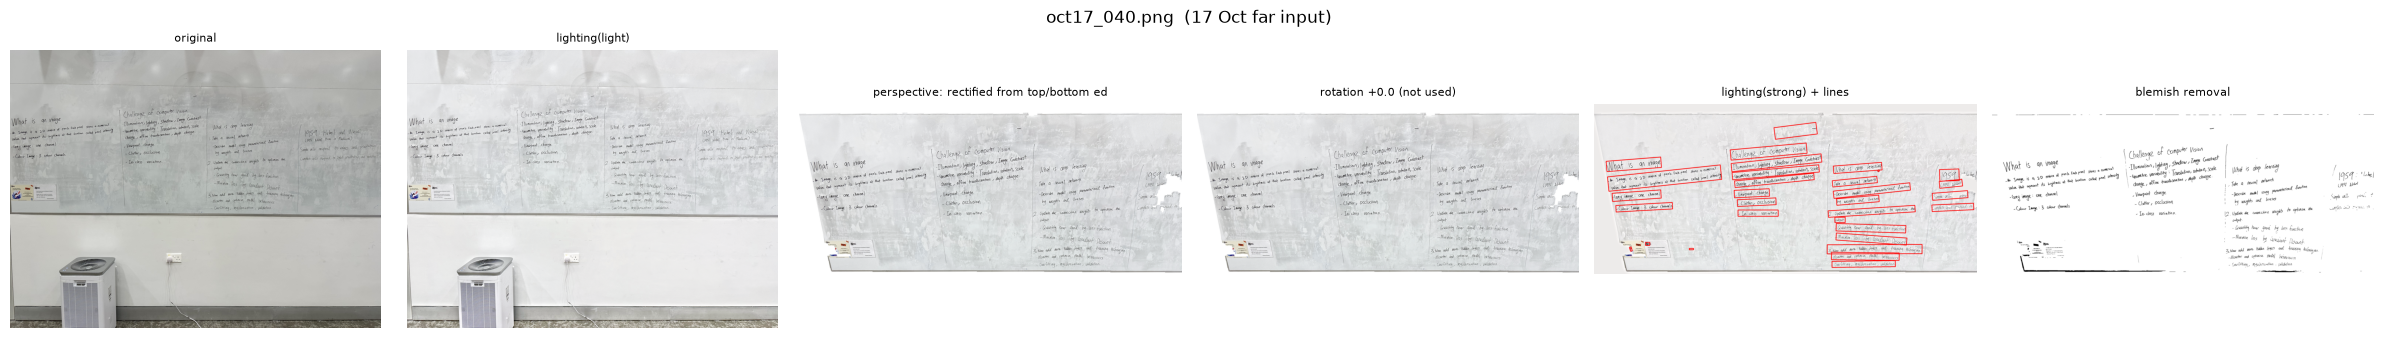

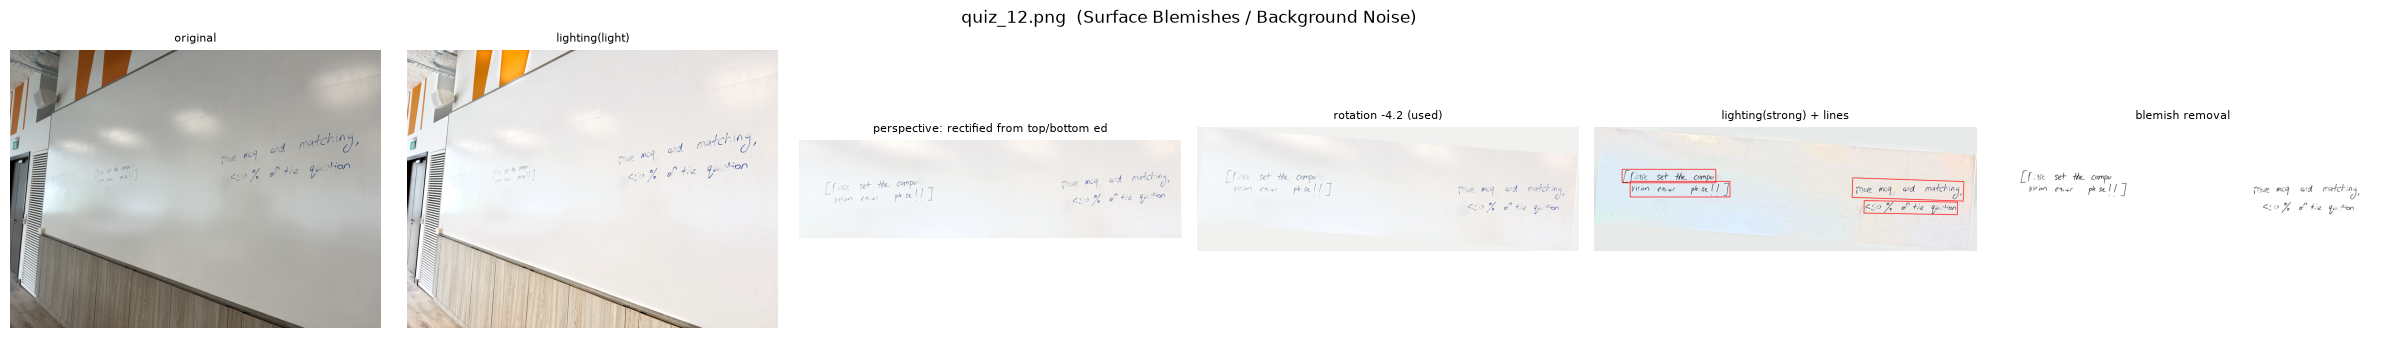

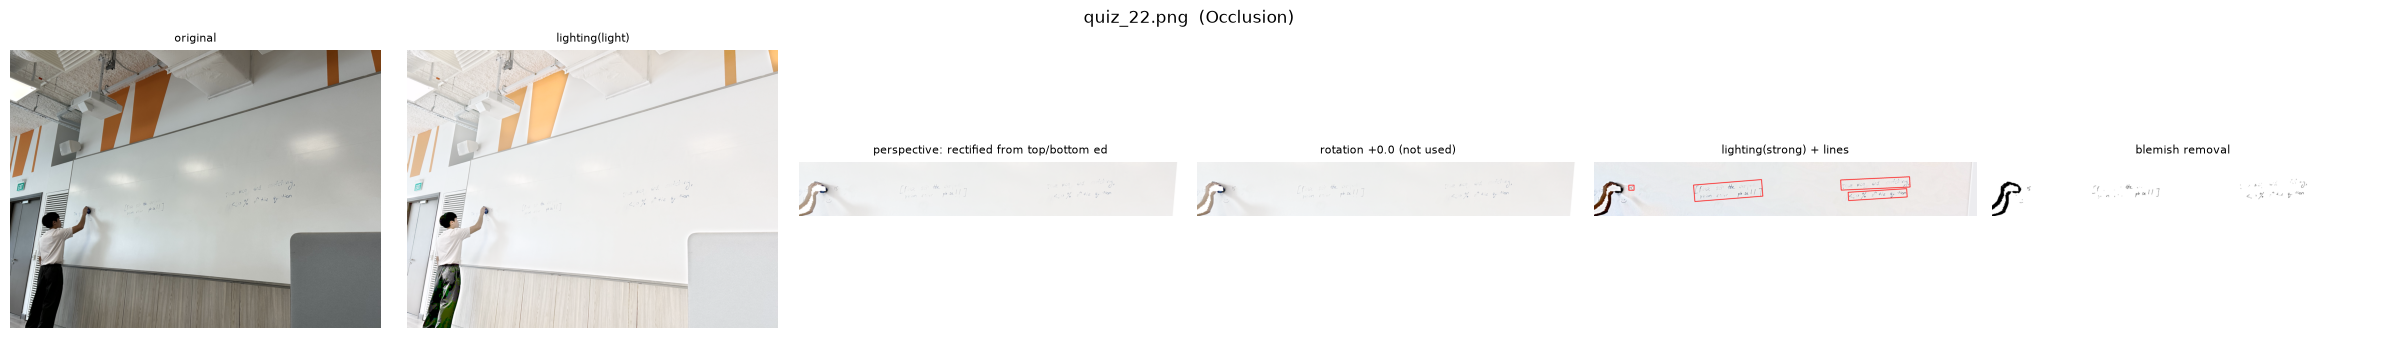

In [4]:
detector, reader = tl.Detector(), tl.Reader()

def stages(f):
    img = cv2.imread(str(DATASET / "images" / f)); f35 = geo.focal35_from_exif(DATASET / "images" / f)
    out = [("original", img)]
    a, _ = fix_lighting.fix(img, strength="light"); out.append(("lighting(light)", a))
    boxes, _ = detector.detect(a, board_mask_fn=geo.segment_board_floodfill, unclip=STEPS.unclip)
    if not boxes:
        return out
    r = geo.auto_rectify(a, boxes, f35=f35)
    b, pts = (r["rectified"], r["text_rect"]) if r["rectified"] is not None else (a, np.vstack(boxes))
    x0, y0, x1, y1 = geo.crop_box(b.shape, pts, P.REGION_MARGIN); b = b[y0:y1, x0:x1]
    out.append((f"perspective: {r['status'][:28]}", b))
    c, rinfo = P._gated_rotation(b); out.append((f"rotation {rinfo['angle']:+.1f} ({'used' if rinfo['used'] else 'not used'})", c))
    d, _ = fix_lighting.fix(c, strength="strong")
    lines = tl.group_into_lines(detector.detect(d, unclip=STEPS.unclip)[0])[0]
    dd = d.copy()
    for p in lines: cv2.polylines(dd, [np.int32(p)], True, (0, 0, 255), max(2, d.shape[1] // 600))
    out.append(("lighting(strong) + lines", dd))
    if lines:
        e, _ = blemish_removal.clean_text_region(d, float(np.median([tl.line_height(p) for p in lines])))
        out.append(("blemish removal", e))
    return out

examples = {}
for f in photos:
    c = L.condition_of(manifest[f])
    if gt.get(f) and c not in examples:
        examples[c] = f
for c, f in examples.items():
    st = stages(f)
    fig, ax = plt.subplots(1, len(st), figsize=(4 * len(st), 3.4))
    for a_, (t, im) in zip(ax, st):
        a_.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a_.set_title(t, fontsize=8); a_.axis("off")
    fig.suptitle(f"{f}  ({c})"); plt.tight_layout(); plt.show()

## 4. Build: every photo -> preprocessed line crops paired with labels

For each photo: the chosen chain, the line crops **as the app feeds them to the reader** (lines under 48 px enlarged), the app's reader reads each crop, and `labels.match_lines` pairs crops with label lines:

* **accepted**: the pairing is trusted: crop shape fits the label length, and either the reading is close (CER <= 0.34) or the neighbouring crops pair with the neighbouring label lines (reading order).
* **review**: paired, but the evidence is weak; shown on a contact sheet in section 5, not used for training unless `INCLUDE_REVIEW = True`.
* **unlabelled**: no label line fits (stray marks, the photo has no labels yet). Saved anyway: the 101 unlabelled 17 Oct photos get crops with the reader's text as a pre-filled suggestion, which makes labelling them later much faster.

Results are cached per photo in `rows/`, so an interrupted run continues where it stopped. Set `REBUILD = True` after changing the chain.

In [5]:
REBUILD = False
OCT17_BY_PHOTO = False      # only for the suggested_split column (section 6): True = by photo, False = by board
ROWS_DIR = OUT / "rows"; ROWS_DIR.mkdir(exist_ok=True)
stamp = dict(chain=CHOSEN, steps=STEPS.name(), oct17_by_photo=OCT17_BY_PHOTO)
if (OUT / "build_settings.json").exists() and json.loads((OUT / "build_settings.json").read_text()) != stamp and not REBUILD:
    raise RuntimeError(f"rows/ was built with other settings {json.loads((OUT / 'build_settings.json').read_text())}; "
                       "set REBUILD = True")
(OUT / "build_settings.json").write_text(json.dumps(stamp))

rows, logs, t0 = [], [], time.time()
for n, f in enumerate(photos, 1):
    cache = ROWS_DIR / f"{Path(f).stem}.json"
    if cache.exists() and not REBUILD:
        d = json.loads(cache.read_text())
    else:
        m = manifest[f]
        info = dict(set=m["set"], board=m["board"], condition=L.condition_of(m),
                    repeat_shot_group=m["repeat_shot_group"])
        try:
            r, lg = DS.process_photo(DATASET / "images" / f, gt.get(f, []), detector, reader, STEPS, OUT, info)
            d = dict(rows=r, log=lg)
        except Exception as e:                      # one bad photo must not stop the build; it is reported below
            d = dict(rows=[], log=dict(photo=f, error=f"{type(e).__name__}: {e}"))
        cache.write_text(json.dumps(d, default=str))
        el = time.time() - t0
        print(f"[{n}/{len(photos)}] {f}: {d['log'].get('crops', 0)} crops, "
              f"{d['log'].get('accepted', 0)} accepted, {d['log'].get('review', 0)} review   ({el / 60:.1f} min)")
    if DS.migrate_crops(d["rows"], OUT):            # crops of the first builds (crops/train, crops/test) -> crops/all
        cache.write_text(json.dumps(d, default=str))
    rows += d["rows"]; logs.append(d["log"])

failed = [l for l in logs if l.get("error")]
print(f"\n{len(rows)} crops from {len(logs)} photos; {len(failed)} photos failed")
for l in failed[:10]:
    print("  ", l["photo"], l["error"])


4483 crops from 250 photos; 0 photos failed


## 5. Second shape check, and the review sheet

First the crops are paired again with the current rules (`labels.py` v2, 23 Oct), from the cached readings, so a rule change needs no rebuild. v2 was added after the first build's accepted crops showed label errors: crops the detector had cut ("3. Viewpoint" labelled "3. Viewpoint Views"), and a printed sign labelled through order support. A crop must now cover its label end to end, and show one text row (v3: crops where the detector merged two lines go to review; the shape check no longer blocks close readings, because it was sending correct single lines with an underline or an arrow to review). Then photos with fewer than 3 confident pairings, which had nothing to compare crop shapes against, are checked against the dataset median. Then a contact sheet of the `review` crops: label (black) vs what the reader read (red). Look through it; crops whose label is right can be approved by adding their `crop` path to `approved_review.txt` (one per line), and they are then treated as accepted.

re-pairing with the current rules (old status -> new): {('accepted', 'accepted'): 1024, ('unlabelled', 'unlabelled'): 2330, ('accepted', 'review'): 124, ('review', 'review'): 951, ('review', 'accepted'): 54}
crops with two or more text rows (detector merged lines): 226
status changed by the dataset-wide shape check: 2
Counter({'unlabelled': 2330, 'review': 1077, 'accepted': 1076})


/var/folders/xl/0nmgmb4d27v2cp2tghhvpkg40000gn/T/ipykernel_7533/404401713.py:23: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout(); plt.show()
/Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Lab/.venv312/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


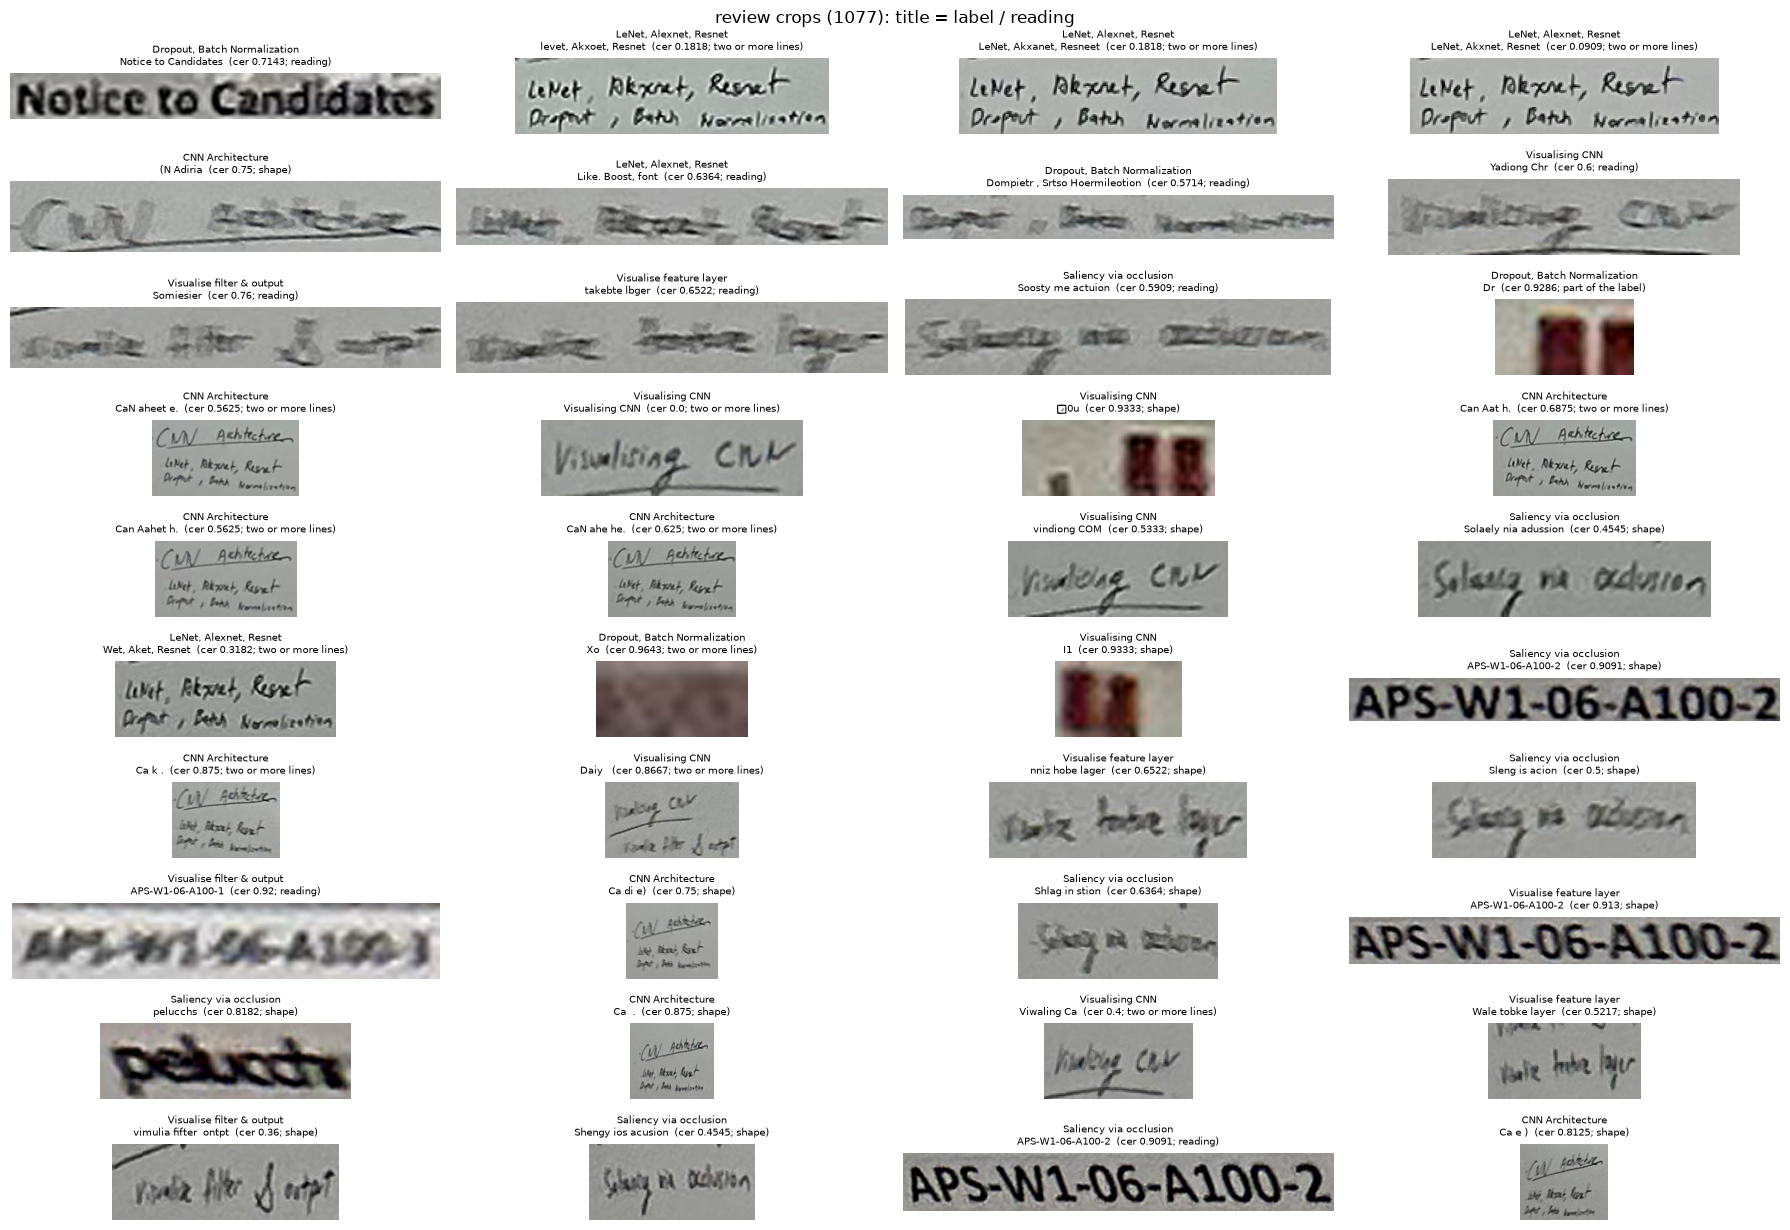

In [6]:
# pair again with the current rules (labels.py v2: ends check, stricter order support and shape), from the
# cached readings: no detection or reading is redone
print("re-pairing with the current rules (old status -> new):", dict(DS.rematch(rows, gt, out_dir=OUT)))
print("crops with two or more text rows (detector merged lines):", sum(r.get("text_rows", 1) > 1 for r in rows))
print("status changed by the dataset-wide shape check:", DS.recheck_shape(rows))
approved_file = OUT / "approved_review.txt"
approved = set(approved_file.read_text().split()) if approved_file.exists() else set()
for r in rows:
    if r["status"] == "review" and r["crop"] in approved:
        r["status"] = "accepted"; r["approved"] = True
print(Counter(r["status"] for r in rows))

def contact_sheet(rs, n=40, cols=4, title=""):
    rs = rs[:n]
    if not rs:
        print("nothing to show"); return
    fig, ax = plt.subplots((len(rs) + cols - 1) // cols, cols, figsize=(4.5 * cols, 1.25 * ((len(rs) + cols - 1) // cols)))
    for a_ in np.ravel(ax): a_.axis("off")
    for a_, r in zip(np.ravel(ax), rs):
        a_.imshow(cv2.cvtColor(cv2.imread(str(OUT / r["crop"])), cv2.COLOR_BGR2RGB))
        why = r.get("ends") or ("shape" if r.get("shape_ok") in (False, "False") else "reading")
        a_.set_title(f"{r['label'][:34]}\n{r['reading'][:34]}  (cer {r['cer']}; {why})", fontsize=7, color="black")
    fig.suptitle(title); plt.tight_layout(); plt.show()

review = sorted((r for r in rows if r["status"] == "review"), key=lambda r: (r["photo"], r["line_no"]))
contact_sheet(review, title=f"review crops ({len(review)}): title = label / reading")

## 6. One folder; the split is made after merging

Every crop is in `crops/all/`. Nothing is split or augmented here: the merged dataset is split first, and the shrunken small-text copies (`DS.shrink_copy`, the app's enlargement applied to a shrunk crop) are then made **for the training part only**, so no copy of a validation or test line ends up in training.

When you split the merged set, split **by board, never by crop**: each line was photographed up to 49 times, so a random crop split puts the same handwriting and the same sentence in training and test, and the test score is inflated. The manifest has what that needs:

| Column | Use |
|---|---|
| `board`, `set` | split unit (README rule: each board entirely in one split) |
| `photo`, `repeat_shot_group` | finer unit if a board must be divided; repeat shots stay together |
| `label` | check that no test text appears in training |
| `suggested_split` | what our rules would give: train = animal, quiz, lecture, 17 Oct; val = television + 20 % of the lecture texts (every crop of a held-out text); test = cnn (the board every earlier result was measured on) |

In [7]:
DS.suggest_split(rows, manifest, OCT17_BY_PHOTO)
c = Counter((r["suggested_split"], r["status"]) for r in rows)
print(f"{'suggested split':<16}" + "".join(f"{s:>12}" for s in ("accepted", "review", "unlabelled")))
for sp in ("train", "val", "test"):
    print(f"{sp:<16}" + "".join(f"{c[(sp, s)]:>12}" for s in ("accepted", "review", "unlabelled")))
print("\naccepted crops by board:", dict(Counter(r["board"] for r in rows if r["status"] == "accepted")))

suggested split     accepted      review  unlabelled
train                    876         812        2134
val                      106         100          27
test                      94         165         169

accepted crops by board: {'animal': 3, 'cnn': 94, 'lecture': 462, 'oct17': 390, 'quiz': 101, 'television': 26}


## 7. Label files and checks

Written to `data/board2notes_rec_v2/`:
* `labels.txt`: every accepted crop, PaddleOCR `SimpleDataSet` format (`<crop path>\t<label>`, paths relative to this folder).
* `labels_ctc38.txt`: the same without labels needing more than 38 CTC steps (length + repeated letter pairs). PP-OCR recognition heads see only **40 time steps in training**; a longer label cannot be learned with a 40-slot config.
* `review.txt`: crops paired with a label but not trusted (section 5). For a person to check; approved ones go into `approved_review.txt` and become accepted on the next run.
* `manifest.csv`: one row per crop with every column above, plus status, reading, CER, box size and text rows.

In [8]:
counts = DS.write_label_file_all(rows, OUT)
DS.write_manifest(rows, OUT / "manifest.csv")
print("label files:", counts)
checks = DS.check_all(rows, OUT)
for name, ok, detail in checks:
    print(f"  {'PASS' if ok else 'FAIL'}  {name}: {detail}")
assert all(ok for _, ok, _ in checks), "a dataset check failed: do not use these files"
long = [r for r in rows if r["status"] == "accepted" and r["ctc_steps"] and r["ctc_steps"] > DS.CTC_SLOTS - DS.CTC_MARGIN]
print(f"accepted labels too long for 40 CTC steps: {len(long)} (in labels.txt only)")
old = [OUT / "train.txt", OUT / "val.txt", OUT / "test.txt"]
if any(p.exists() for p in old):
    print("NOTE: train/val/test .txt files from an earlier version are still in the folder; they are outdated.")

label files: {'labels.txt': 1076, 'labels_ctc38.txt': 1017, 'review.txt': 1077}
  PASS  every crop file exists: 0 missing
  PASS  all crops in one folder: folders: ['crops/all']
  PASS  every labelled crop has a label: 0 empty labels
  PASS  no identical crop with two different labels: 0 clashes
  PASS  grouping columns present for a later split: board, photo, repeat_shot_group, label, suggested_split
accepted labels too long for 40 CTC steps: 59 (in labels.txt only)
NOTE: train/val/test .txt files from an earlier version are still in the folder; they are outdated.


## 8. What the pretrained reader makes of these crops (baseline, and the selection-bias check)

The CER of the app's pretrained reader on the accepted crops, by board: what a fine-tuned reader has to beat, once the split exists. The column on the right shows how many accepted crops the old rule (keep only if the pretrained reader's CER <= 0.25) would have thrown away.

Caveat: the pairing still relies on the pretrained reader for most crops (CER <= 0.34), so this baseline is optimistic; the hardest lines are in `review.txt`.

board         accepted  mean CER  CER > 0.25   texts
animal               3     0.000           0       1
cnn                 94     0.154          15       7
lecture            462     0.073          29     136
oct17              390     0.041           5      73
quiz               101     0.092           6       6
television          26     0.004           0       2

by condition (accepted crops):
  17 Oct close target                           61 crops   CER 0.043   enlarged 0%
  17 Oct far input                             157 crops   CER 0.045   enlarged 68%
  17 Oct medium input                          112 crops   CER 0.017   enlarged 0%
  17 Oct side angle input                       60 crops   CER 0.074   enlarged 50%
  Clean / Control                              170 crops   CER 0.040   enlarged 21%
  Occlusion                                      4 crops   CER 0.072   enlarged 0%
  Perspective Distortion                       240 crops   CER 0.083   enlarged 14%
  Scale and 

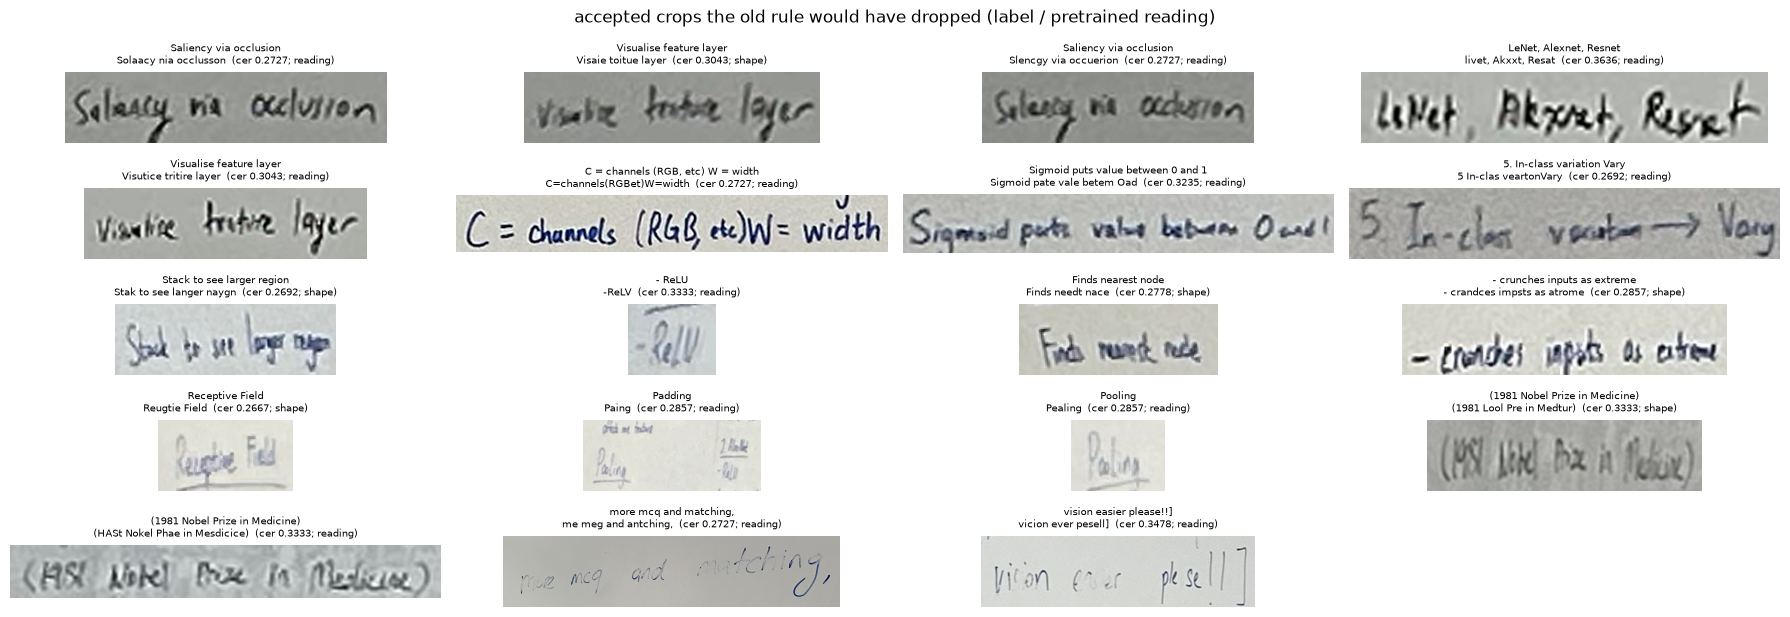

In [9]:
def mean_cer(rs):
    v = [r["cer"] for r in rs if r["cer"] is not None]
    return (np.mean(v), len(v)) if v else (float("nan"), 0)

print(f"{'board':<12}{'accepted':>10}{'mean CER':>10}{'CER > 0.25':>12}{'texts':>8}")
for b in sorted({r["board"] for r in rows}):
    acc = [r for r in rows if r["board"] == b and r["status"] == "accepted"]
    m, n = mean_cer(acc)
    hard = sum(r["cer"] is not None and r["cer"] > 0.25 for r in acc)
    print(f"{b:<12}{n:>10}{m:>10.3f}{hard:>12}{len({r['label'] for r in acc}):>8}")

print("\nby condition (accepted crops):")
by = defaultdict(list)
for r in rows:
    if r["status"] == "accepted":
        by[r["condition"]].append(r)
for c, rs in sorted(by.items()):
    m, n = mean_cer(rs)
    print(f"  {c:<42}{n:>6} crops   CER {m:.3f}   enlarged {sum(r['enlarged'] for r in rs) / n:.0%}")

contact_sheet([r for r in rows if r["status"] == "accepted" and r["cer"] and r["cer"] > 0.25][::3],
              title="accepted crops the old rule would have dropped (label / pretrained reading)")

## 9. Hand-over

* Folder: `whiteboard-ocr/data/board2notes_rec_v2/` with `crops/all/`, `labels.txt` (or `labels_ctc38.txt`), `review.txt`, `manifest.csv`.
* Merging: concatenate `labels.txt` with the other datasets' label files (paths relative to each dataset's folder, or rewrite them to one root), and keep a column saying which dataset each line came from.
* Splitting: by board (`board` column), with repeat shots together; check that no test `label` appears in training. Our own suggestion is in `suggested_split`.
* After the split: shrunken small-text copies for the training part only (`DS.shrink_copy`), then train; report the result on the test boards only.